# HPD 1 — Pipeline de embeddings y búsqueda semántica

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Adamychen/m10_quarto/blob/main/notebooks/bloque1/hpd1-embeddings.ipynb)

> **Competencias:** [CE-1](../index.qmd#sec-competencias-especificas)

> **Objetivos**
>
> - Construir un pipeline de embeddings end-to-end
> - Usar LangChain para carga de PDFs y chunking con solapamiento
> - Generar embeddings con un modelo open-source
> - Indexar en Chroma y ejecutar búsqueda semántica
> - Evaluar la calidad con un ground truth definido por contenido
>   (recall@k, hit@k y MRR)
> - Comparar la búsqueda densa con una línea base léxica (BM25) y con la
>   búsqueda híbrida
> - Validar el modelo con benchmarks estándar (MTEB) y entender sus
>   límites
>
> ## Materiales
>
> - Librerías: `langchain`, `langchain-text-splitters`,
>   `sentence-transformers`, `chromadb`, `pypdf`, `fpdf2`, `arxiv`,
>   `mteb`
> - Modelo: `intfloat/e5-small-v2`
> - Corpus: abstracts reales de ArXiv convertidos a PDF con `fpdf2`
> - Corpus real: 6 papers de ArXiv
>
> ## Pipeline
>
> 1.  **Parte 1 — Aproximación conceptual:** abstracts reales, ejecutar
>     un pipeline completo sobre un ejemplo pequeño
> 2.  **Parte 2 — Escenario realista:** corpus real de ArXiv (~1.300
>     chunks), evaluación con consultas difíciles, comparación BM25 /
>     denso / híbrido y evaluación MTEB

> **¿Por qué necesitas esto?**
>
> Imagina que trabajas en un despacho de abogados buscando cláusulas de
> confidencialidad en 500 contratos. O en una multinacional filtrando
> currículums por habilidades, no por palabras clave exactas. O en un
> hospital recuperando historiales clínicos con síntomas parecidos. Los
> tres problemas se resuelven con la misma arquitectura: convertir
> documentos en vectores y buscar por similitud semántica.
>
> Al final de este taller sabrás construir ese pipeline de principio a
> fin y, sobre todo, **medir si funciona**. Y lo mejor: cambiar de
> dominio (legal, médico, financiero) solo requiere cambiar los
> documentos de entrada — el código es el mismo.

## Del recorrido histórico al pipeline

El [panorama histórico del Bloque 1](00-panorama.qmd) termina en la idea
de que un documento y una consulta pueden situarse en un mismo espacio
semántico. Este taller convierte esa idea en un sistema ejecutable:
ingesta de documentos, chunking, embeddings, indexación, recuperación y
evaluación. El objetivo no es solo llamar a un modelo, sino comprobar
qué calidad tiene la representación cuando se utiliza para recuperar
información.

> **Antes de empezar**
>
> Activa antes la GPU gratuita en *Entorno de ejecución → Cambiar tipo
> de entorno de ejecución → GPU T4*: con ella, calcular los embeddings
> pasa de minutos a segundos. Si Colab no te da GPU libre, el taller
> funciona igual con CPU, solo que esas celdas tardan más. Ejecuta
> **ya** la celda de instalación de más abajo y sigue leyendo mientras
> termina: tarda unos 2 minutos. Si al acabar aparece un aviso en rojo
> sobre *dependency conflicts* (`google-colab`, `requests`,
> `opentelemetry`), ignóralo: son paquetes que trae Colab y no afectan a
> este taller.

In [1]:
!pip install -q chromadb==1.5.9 sentence-transformers==5.5.1 fpdf2==2.8.7 arxiv==4.0.0 mteb==2.12.30 matplotlib scikit-learn "pandas<3" langchain==1.3.2 langchain-community==0.3.31 langchain-text-splitters==1.1.2 pypdf==6.12.2 langchain-core==1.4.0 langgraph==1.2.2 openai==2.38.0

In [2]:
import os
import tempfile
import shutil
import requests
import arxiv
import matplotlib.pyplot as plt
import pandas as pd
from fpdf import FPDF
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
from langchain_community.document_loaders import PyPDFLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
import chromadb
import numpy as np

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 100

# ------------------------------------------------------------------ Parámetros compartidos
CHUNK_SIZE = 300      # caracteres por chunk  (antes usábamos palabras; ahora LangChain usa caracteres)
CHUNK_OVERLAP = 50    # caracteres de solapamiento
MODEL_NAME = "intfloat/e5-small-v2"

# ------------------------------------------------------------------ Directorios temporales
BASE_DIR = tempfile.mkdtemp()
CORPUS_SINTETICO = os.path.join(BASE_DIR, "corpus_sintetico")
CORPUS_REAL = os.path.join(BASE_DIR, "corpus_real")
os.makedirs(CORPUS_SINTETICO)
os.makedirs(CORPUS_REAL)
print(f"Directorio temporal: {BASE_DIR}")

# ------------------------------------------------------------------ Modelo de embeddings
model = SentenceTransformer(MODEL_NAME)
print(f"Modelo cargado: {MODEL_NAME}")
print(f"  Dimensión de embeddings: {model.get_embedding_dimension()}")

# ------------------------------------------------------------------ Funciones de embedding (modelo E5)
def embed_passages(textos):
    """Documentos/chunks. E5 espera el prefijo 'passage: '. Se codifica por lotes y normalizado."""
    return model.encode(["passage: " + t for t in textos], normalize_embeddings=True,
                        batch_size=64, show_progress_bar=False)

def embed_queries(textos):
    """Consultas. E5 espera el prefijo 'query: '."""
    return model.encode(["query: " + t for t in textos], normalize_embeddings=True,
                        show_progress_bar=False)

# ------------------------------------------------------------------ Chroma (cliente compartido)
client = chromadb.EphemeralClient()

------------------------------------------------------------------------

# Parte 1 — Aproximación conceptual

En esta primera parte construimos el pipeline completo sobre un corpus
de 3 PDFs generados con los abstracts reales de papers de ArXiv:
*Attention Is All You Need*, *Sentence-BERT* y *RAG*. Son los mismos
papers que indexaremos completos en la Parte 2.

## 1.1 Corpus: abstracts reales de ArXiv

Usamos `arxiv` para descargar los abstracts de 3 papers clave del
módulo. Con `fpdf2` los convertimos en PDFs para que el pipeline de
ingesta (carga → chunking → indexación) sea idéntico al que usarás con
documentos reales.

In [3]:
class PDF(FPDF):
    pass

def crear_pdf(nombre: str, titulo: str, contenido: str) -> None:
    pdf = PDF()
    pdf.add_page()
    pdf.set_font("Helvetica", "B", 16)
    pdf.cell(0, 10, titulo, new_x="LMARGIN", new_y="NEXT")
    pdf.ln(5)
    pdf.set_font("Helvetica", "", 11)
    pdf.multi_cell(0, 6, contenido)
    pdf.output(os.path.join(CORPUS_SINTETICO, nombre))
    print(f"  ✅ {nombre}")

# Descargar abstracts de ArXiv
arxiv_client = arxiv.Client()
ABSTRACT_IDS = ["1706.03762", "1908.10084", "2005.11401"]
search = arxiv.Search(id_list=ABSTRACT_IDS)

abstracts = {}
for paper in arxiv_client.results(search):
    aid = paper.get_short_id().split("v")[0]
    abstracts[aid] = (paper.title, paper.summary.replace("\n", " ").strip())
    print(f"  ✅ {aid}: {paper.title[:70]}...")

# Construir el corpus con los abstracts
corpus = {
    f"{aid}.pdf": (title, summary)
    for aid, (title, summary) in abstracts.items()
}

print("Generando PDFs con abstracts reales...")
for nombre, (titulo, contenido) in corpus.items():
    crear_pdf(nombre, titulo, contenido)
print(f"Corpus generado: {len(corpus)} PDFs en {CORPUS_SINTETICO}")

## 1.2 Carga de PDFs con LangChain

`PyPDFLoader` carga documentos PDF y devuelve una lista de objetos
`Document` de LangChain. Cada `Document` tiene `.page_content` (texto) y
`.metadata` (fuente, nº de página, etc.).

In [4]:
def cargar_pdfs(dir_path: str) -> list:
    """
    Carga todos los PDFs de un directorio usando PyPDFLoader de LangChain.

    Args:
        dir_path: Ruta al directorio con archivos .pdf

    Returns:
        list[Document]: Documentos LangChain con page_content y metadata.
    """
    documentos = []

    for filename in sorted(os.listdir(dir_path)):
        ruta = os.path.join(dir_path, filename)

        if filename.endswith(".txt"):          # abstracts de respaldo (si falla la descarga de PDFs)
            documentos.extend(TextLoader(ruta, encoding="utf-8").load())
            continue
        if not filename.endswith(".pdf"):
            continue

        # TODO: Crear un PyPDFLoader con la ruta del archivo
        # TODO: Llamar a loader.load() para obtener los Document
        # TODO: Extender la lista documentos con los documentos cargados

    return documentos


docs = cargar_pdfs(CORPUS_SINTETICO)
print(f"Documentos cargados: {len(docs)}")
for doc in docs:
    print(f"  {doc.metadata.get('source', '?')}: {len(doc.page_content)} caracteres")

> **¿Qué es un embedding?**
>
> Un embedding convierte un texto en una lista de números (384 en
> nuestro caso). La clave está en que textos con significado parecido
> producen números parecidos, aunque usen palabras distintas.
>
> Imagina un mapa donde cada documento es un punto. Los documentos que
> hablan de lo mismo quedan cerca. Cuando haces una pregunta, el modelo
> la sitúa en ese mismo mapa y busca los vecinos más próximos.
>
> El modelo que usamos, `e5-small-v2`, tiene solo 33 millones de
> parámetros: ligero para ejecutar en local pero con muy buena calidad
> para búsqueda semántica.

## 1.3 Chunking con RecursiveCharacterTextSplitter

En vez de partir a mano por palabras, usamos
`RecursiveCharacterTextSplitter` de LangChain: intenta cortar por
párrafos (`\n\n`), luego por saltos de línea, luego por frases (`.`) y
por último por espacios. Así los chunks mantienen sentido y no se cortan
a mitad de una frase.

In [5]:
# TODO: Crear un RecursiveCharacterTextSplitter configurando:
#   chunk_size       — caracteres por chunk
#   chunk_overlap    — caracteres de solapamiento
#   separators       — ["\n\n", "\n", ". ", " ", ""] (orden de preferencia)

splitter = None  # ← completar

# TODO: Llamar a splitter.split_documents(docs) para dividir los documentos
chunks = None  # ← completar

print(f"Chunks generados: {len(chunks)}")
for i, chunk in enumerate(chunks):
    fuente = os.path.basename(chunk.metadata["source"])
    print(f"  [{i}] {fuente}: {len(chunk.page_content)} caracteres")

## 1.4 Embeddings e indexación en Chroma

Todos los chunks se codifican **en un solo lote** (mucho más rápido que
de uno en uno) y se insertan en la colección vectorial.

> **Los prefijos `query:` y `passage:` de E5**
>
> La familia E5 se entrenó con un prefijo distinto para consultas
> (`query:`) y documentos (`passage:`), y su ficha pide usarlos. Las
> funciones `embed_queries` y `embed_passages` de la celda de
> configuración ya lo hacen por ti. ¿Importan mucho? **Mídelo, no lo
> asumas:** en una prueba nuestra con `e5-small-v2` sobre 5.400
> documentos de FiQA, omitirlos cambió el recall@10 en medio punto
> (0,716 frente a 0,721). Esa prueba usa **otra muestra** de FiQA,
> distinta de la del entregable (otras consultas y otro tamaño de
> corpus), así que sus cifras **no son comparables** con las de las 50
> consultas del entregable. Poco, pero otros modelos y otros corpus
> pueden comportarse distinto, y seguir la ficha del modelo no cuesta
> nada.

In [6]:
collection = client.get_or_create_collection(
    name="hpd1_sintetico",
    metadata={"hnsw:space": "cosine"}
)

print("Generando embeddings e indexando...")
embeddings_chunks = embed_passages([c.page_content for c in chunks])    # un solo lote

contador = {}     # índice del chunk DENTRO de cada documento
for chunk, embedding in zip(chunks, embeddings_chunks):
    fuente = os.path.basename(chunk.metadata["source"])
    contador[fuente] = contador.get(fuente, -1) + 1
    idx_local = contador[fuente]
    chunk_id = f"{os.path.splitext(fuente)[0]}_chunk_{idx_local}"

    # TODO: collection.add() con:
    #   ids          — [chunk_id]
    #   embeddings   — [embedding.tolist()]
    #   documents    — [chunk.page_content]
    #   metadatas    — [{"fuente": fuente, "chunk_index": idx_local}]

print(f"Indexación completada: {collection.count()} vectores en Chroma")

> **¿Chroma, FAISS, pgvector o Qdrant? ¿Cuál elijo?**
>
> La comparativa completa, con criterios de escala, latencia y
> privacidad, está en [01d](01d-vectordb.qmd#sec-comparativa-vdb). Para
> este taller basta la regla práctica: **empieza con Chroma** (local,
> sin servidor, guarda texto y metadatos). Con unos miles de chunks una
> búsqueda exacta tarda milisegundos y no necesitas nada más
> sofisticado; si el proyecto crece, el flujo (embeddings → indexar con
> metadatos → consultar) se traslada a otro motor. Lo usamos en HPD 1 y
> en HPD 5.

## 1.5 Búsqueda semántica

La consulta se codifica y se recuperan los `k` chunks más similares por
distancia coseno. Modelo y corpus están en inglés, así que la consulta
también (recuerda: [modelo e idioma deben ir a
juego](01c-embeddings.qmd#sec-fallo-idioma); en el ejercicio E1 lo
pondrás a prueba).

In [7]:
def buscar(collection, query: str, k: int = 5) -> dict:
    """
    Realiza una búsqueda semántica en una colección vectorial.

    Args:
        collection: Colección de Chroma donde buscar.
        query: Consulta en lenguaje natural.
        k: Número de resultados a recuperar.

    Returns:
        dict: Resultado de Chroma con ids, distances, documents y metadatas.
    """
    query_embedding = embed_queries([query])[0].tolist()

    # TODO: Llamar a collection.query() con:
    #   query_embeddings — [query_embedding]
    #   n_results        — k

    return resultados


PREGUNTA = "How does the attention mechanism work in Transformers?"
resultados = buscar(collection, PREGUNTA, k=3)
print(f"\nResultados para: '{PREGUNTA}'")
for i, (chunk_id, distancia, texto) in enumerate(zip(
    resultados["ids"][0],
    resultados["distances"][0],
    resultados["documents"][0],
)):
    print(f"\n  {i + 1}. {chunk_id}  (distancia: {distancia:.4f})")
    print(f"     {texto[:150]}...")

> **Similitud coseno vs. distancia coseno**
>
> Chroma devuelve distancias, no similitudes. La relación es:
>
> $$\text{distancia} = 1 - \text{similitud}$$
>
> | Métrica | Rango | Interpretación |
> |------------------------|------------------------|------------------------|
> | **Similitud coseno** | $[-1, 1]$ | $1$ = idénticos, $0$ = ortogonales, $-1$ = opuestos |
> | **Distancia coseno** | $[0, 2]$ | $0$ = idénticos, $1$ = ortogonales, $2$ = opuestos |
>
> Table 1: Comparativa entre similitud coseno y distancia coseno
>
> Con embeddings normalizados (lo habitual), la similitud coseno
> equivale al producto escalar y oscila en $[0, 1]$. La distancia, por
> tanto, está en $[0, 1]$. Cuanto menor es la distancia, más relevante
> es el chunk.

## 1.6 Más allá del texto: embeddings de datos tabulares

Hasta ahora hemos hecho embeddings de PDFs. Pero ¿y si tus datos están
en un Excel? La buena noticia: el pipeline no cambia. Solo cambia cómo
conviertes cada fila en texto.

In [8]:
# Dataset tabular de ejemplo: empleados
df_empleados = pd.DataFrame({
    "nombre":       ["Ana García", "Carlos Ruiz", "Beatriz López", "David Martín"],
    "departamento": ["I+D",        "Ventas",       "I+D",           "Operaciones"],
    "salario":      [55000,        47000,          48000,           51000],
    "antiguedad":   [7,            4,              3,               5],
})

# Convertir cada fila en un "documento" textual
df_empleados["documento"] = df_empleados.apply(
    lambda r: f"Empleado {r['nombre']}. Departamento {r['departamento']}. "
              f"Salario {r['salario']} euros. Antigüedad {r['antiguedad']} años.",
    axis=1
)

print("Filas convertidas a texto:")
for doc in df_empleados["documento"]:
    print(f"  → {doc}")

# Mismo modelo, mismo encode(), mismo pipeline
embeddings_tab = embed_passages(df_empleados["documento"].tolist())
print(f"\nEmbeddings tabulares: {embeddings_tab.shape}")

In [9]:
# Indexar en Chroma — idéntico a como hiciste con PDFs
collection_tab = client.get_or_create_collection(
    name="hpd1_tabular",
    metadata={"hnsw:space": "cosine"}
)

for i, (_, row) in enumerate(df_empleados.iterrows()):
    collection_tab.add(
        ids=[f"emp_{i}"],
        embeddings=[embeddings_tab[i].tolist()],
        documents=[row["documento"]],
        metadatas=[{"nombre": row["nombre"], "departamento": row["departamento"]}]
    )

print(f"Indexación completada: {collection_tab.count()} vectores en Chroma")

# Buscar: "empleados senior de I+D"
res = collection_tab.query(
    query_embeddings=[embed_queries(["empleados senior de I+D"])[0].tolist()],
    n_results=2
)
print("\nBúsqueda: 'empleados senior de I+D'")
for doc, dist in zip(res["documents"][0], res["distances"][0]):
    print(f"  {doc[:80]}... (dist: {dist:.4f})")

> **¿Qué modelo de embeddings uso según mi tipo de dato?**
>
> | Tipo de dato | Modelo recomendado | ¿Requiere entrenamiento? |
> |------------------------|------------------------|------------------------|
> | **Texto** (PDFs, webs, emails) | `e5-small-v2`, `text-embedding-3-small` | No, vienen pre-entrenados |
> | **Tabular (rápido)** | Texto concatenado + `e5-small-v2` | No, usas el mismo modelo |
> | **Tabular (riguroso)** | SCARF (aprendizaje contrastivo, autosupervisado) | Sí: hay que entrenarlo con tus propios datos |
> | **Código fuente** | CodeBERT, UnixCoder | No, vienen pre-entrenados |
> | **Imágenes + texto** | CLIP | No, pre-entrenado multimodal |
>
> Table 2: Modelos de embeddings recomendados por tipo de dato
>
> La clave: el pipeline (`encode → index → search`) es el mismo. Solo
> cambia el modelo de embeddings. Si cambias de dominio, cambias los
> documentos de entrada, no el código.

> **Limitación honesta del texto concatenado**
>
> Este enfoque no sabe que 55000 está numéricamente más cerca de 52000
> que de 12000. Compruébalo:
>
> ``` python
> for consulta in ["empleado con salario de 51000 euros", "empleado con salario de 12000 euros"]:
>     res = collection_tab.query(query_embeddings=[embed_queries([consulta])[0].tolist()], n_results=4)
>     print(f"\n{consulta}")
>     for meta, dist in zip(res["metadatas"][0], res["distances"][0]):
>         print(f"   {meta['nombre']:<15} distancia {dist:.3f}")
> ```
>
> Observa dos cosas: las distancias son casi idénticas entre empleados
> (el modelo capta “es un empleado con salario”, no la cifra) y un
> salario que no existe (12000) devuelve resultados igual de “cercanos”
> que uno que sí existe. Para criterios numéricos exactos (salario \>
> 50000, antigüedad \> 6 años) la solución habitual no es un embedding
> mejor sino **combinar la búsqueda semántica con filtros por
> metadatos** (`where=` en Chroma, o SQL). Existen modelos específicos
> para filas tabulares, como SCARF, pero hay que entrenarlos con tus
> datos.
>
> Para muchos casos de búsqueda por descripción (buscar empleados por
> perfil, productos por características, registros por texto libre) el
> texto concatenado es un buen punto de partida; para filtros por
> cifras, no.

## 1.7 Evaluación: recall@k, hit@k y MRR

> **¿Cómo se mide si la búsqueda funciona?**
>
> Necesitamos preguntas de prueba y saber qué chunks son **relevantes**
> para cada una (el *ground truth*). Con ellos:
>
> - **recall@k:** de todos los chunks relevantes, ¿qué fracción aparece
>   entre los $k$ primeros?
> - **hit@k:** ¿hay al menos un relevante entre los $k$ primeros?
>   (sí/no)
> - **MRR:** $1/\text{posición}$ del primer relevante, promediado.
>
> Si una pregunta tiene 5 chunks relevantes y $k=1$, el recall@1 solo
> puede valer 0,2 como máximo aunque el sistema sea perfecto. Por eso
> con $k$ pequeño y varios relevantes conviene mirar también hit@k.
>
> **¿Cómo decidimos qué chunk es relevante?** *Por su contenido*: un
> chunk es relevante para una pregunta si pertenece al documento
> correcto y contiene alguna de las frases clave que anotamos a mano.
> Así el ground truth sigue siendo válido aunque cambies `CHUNK_SIZE`
> (si lo definiéramos con identificadores como `doc_chunk_3`, cada
> cambio de troceado lo invalidaría).

In [11]:
def ids_relevantes(collection, fuente_id, frases):
    """IDs de los chunks del documento `fuente_id` cuyo texto contiene alguna de las frases (ground truth por contenido)."""
    datos = collection.get(include=["documents", "metadatas"])
    return [cid for cid, texto, meta in zip(datos["ids"], datos["documents"], datos["metadatas"])
            if meta["fuente"].startswith(fuente_id) and any(f in texto.lower() for f in frases)]


def recall_at_k(retrieved_ids: list, relevant_ids: list, k: int) -> float:
    """
    Calcula recall@k: proporción de chunks relevantes recuperados en el top-k.

    Args:
        retrieved_ids: IDs recuperados por el sistema (ordenados por relevancia).
        relevant_ids: IDs relevantes (ground truth).
        k: Ventana de resultados a considerar.

    Returns:
        float: recall@k ∈ [0, 1].
    """
    if len(relevant_ids) == 0:
        return 0.0

    # TODO: Tomar los primeros k IDs recuperados
    # TODO: Contar cuántos IDs relevantes aparecen en el top-k
    # TODO: Dividir entre el total de IDs relevantes

    return ...  # ← completar


def hit_at_k(retrieved_ids, relevant_ids, k):
    """1.0 si algún relevante aparece entre los k primeros, 0.0 si no."""
    return float(any(r in relevant_ids for r in retrieved_ids[:k]))


def reciprocal_rank(retrieved_ids, relevant_ids):
    """1/posición del primer relevante (0.0 si no aparece)."""
    for pos, r in enumerate(retrieved_ids, start=1):
        if r in relevant_ids:
            return 1.0 / pos
    return 0.0


# (consulta) -> (documento correcto, frases clave que debe contener un chunk relevante)
QUERIES_PRUEBA = {
    "How does multi-head attention work?":            ("1706.03762", ["attention"]),
    "What are sentence embeddings?":                  ("1908.10084", ["sentence embeddings"]),
    "How does RAG combine retrieval with generation?": ("2005.11401", ["non-parametric", "retriev"]),
    "What is the Transformer architecture?":          ("1706.03762", ["transformer"]),
    "What tasks does RAG improve?":                   ("2005.11401", ["tasks", "qa"]),
}

print("Evaluación — corpus con abstracts reales")
print("=" * 60)

for q, (fuente_id, frases) in QUERIES_PRUEBA.items():
    print(f"  {len(ids_relevantes(collection, fuente_id, frases))} chunks relevantes · {q}")

for k in [1, 3, 5]:
    recalls, hits, rrs = [], [], []
    for query, (fuente_id, frases) in QUERIES_PRUEBA.items():
        relevantes = ids_relevantes(collection, fuente_id, frases)
        retrieved = buscar(collection, query, k=10)["ids"][0]
        recalls.append(recall_at_k(retrieved, relevantes, k))
        hits.append(hit_at_k(retrieved, relevantes, k))
        rrs.append(reciprocal_rank(retrieved, relevantes))

    print(f"\n  k = {k}")
    print(f"    recall@{k} individuales: {[f'{r:.2f}' for r in recalls]}")
    print(f"    recall@{k} medio: {np.mean(recalls):.3f} · hit@{k} medio: {np.mean(hits):.2f} · MRR: {np.mean(rrs):.3f}")

> **Qué observar**
>
> Con pocos chunks por documento, recall@1 es bajo porque cada pregunta
> tiene varios chunks relevantes y solo miras uno. Compáralo con hit@1 y
> con recall@5. Estas dos lecturas juntas dicen algo distinto: *¿el
> primer resultado es bueno?* frente a *¿he encontrado todo lo
> relevante?*

## Limpieza parte 1

In [12]:
client.delete_collection("hpd1_sintetico")
client.delete_collection("hpd1_tabular")
shutil.rmtree(CORPUS_SINTETICO)
print("✅ Parte 1 limpiada (colecciones + corpus temporal eliminados)")

------------------------------------------------------------------------

# Parte 2 — Escenario realista

En esta segunda parte repetimos el pipeline sobre un corpus real: 6
papers descargados de ArXiv. Además añadimos una evaluación profesional
con MTEB para validar la calidad del modelo de embeddings.

## 2.1 Corpus real — Descarga de ArXiv

In [13]:
PAPERS = {
    "1706.03762": "Attention Is All You Need (@vaswani2017attention)",
    "1810.04805": "BERT: Pre-training of Deep Bidirectional Transformers (@devlin2019bert)",
    "1908.10084": "Sentence-BERT (@reimers2019sbert)",
    "2005.11401": "RAG: Retrieval-Augmented Generation (@lewis2020rag)",
    "2106.09685": "LoRA: Low-Rank Adaptation (@hu2022lora)",
    "2309.15217": "RAGAS: Automated Evaluation (@es2024ragas)",
}

def descargar_paper(arxiv_id: str, dir_path: str) -> str:
    """Descarga un paper de ArXiv por ID, con caché local."""
    ruta_pdf = os.path.join(dir_path, f"{arxiv_id}.pdf")
    if os.path.exists(ruta_pdf):
        return ruta_pdf

    client_arxiv = arxiv.Client()
    search = arxiv.Search(id_list=[arxiv_id])
    paper = next(client_arxiv.results(search))
    response = requests.get(paper.pdf_url)
    with open(ruta_pdf, "wb") as f:
        f.write(response.content)
    return ruta_pdf


for arxiv_id, descripcion in PAPERS.items():
    try:
        ruta = descargar_paper(arxiv_id, CORPUS_REAL)
        size_kb = os.path.getsize(ruta) / 1024
        print(f"  ✅ {arxiv_id}: {descripcion[:60]}... ({size_kb:.0f} KB)")
    except Exception as e:
        print(f"  ⚠️ {arxiv_id}: descarga fallida ({e}) — continuando con abstracts pre-guardados")
        # Si no se pueden descargar los PDFs, usamos abstracts inline
        abstracts_fallback = {
            "1706.03762": "Attention Is All You Need — The dominant sequence transduction models are based on complex recurrent or convolutional neural networks that include an encoder and a decoder. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show that these models are superior in quality while being more parallelizable and requiring significantly less time to train.",
            "1810.04805": "BERT: Pre-training of Deep Bidirectional Transformers — We introduce a new language representation model called BERT, which stands for Bidirectional Encoder Representations from Transformers. Unlike recent language representation models, BERT is designed to pre-train deep bidirectional representations from unlabeled text by jointly conditioning on both left and right context in all layers. As a result, the pre-trained BERT model can be fine-tuned with just one additional output layer to create state-of-the-art models for a wide range of tasks.",
            "1908.10084": "Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks — BERT and RoBERTa set new state-of-the-art performance on semantic textual similarity tasks. However, they require both sentences to be fed into the network, causing a massive computational overhead. We present Sentence-BERT, a modification of the pretrained BERT network that uses siamese and triplet network structures to derive semantically meaningful sentence embeddings that can be compared using cosine similarity.",
            "2005.11401": "RAG: Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks — We explore a general-purpose fine-tuning recipe for retrieval-augmented generation (RAG). RAG models combine pre-trained parametric memory (a sequence-to-sequence model) with non-parametric memory (a dense vector index of Wikipedia). We fine-tune and evaluate RAG on a range of knowledge-intensive NLP tasks and set the state of the art on three open-domain QA tasks.",
            "2106.09685": "LoRA: Low-Rank Adaptation of Large Language Models — We propose Low-Rank Adaptation (LoRA), which freezes the pre-trained model weights and injects trainable rank decomposition matrices into each layer of the Transformer architecture, greatly reducing the number of trainable parameters for downstream tasks. Compared to GPT-3 175B fine-tuned with Adam, LoRA reduces trainable parameters by 10,000x and GPU memory requirement by 3x.",
            "2309.15217": "RAGAS: Automated Evaluation of Retrieval Augmented Generation — We introduce RAGAS (Retrieval Augmented Generation Assessment), a framework for reference-free evaluation of RAG pipelines. RAGAS provides a suite of metrics to evaluate different dimensions of RAG systems without requiring ground-truth human annotations: faithfulness, answer relevancy, and context precision among others.",
        }
        if arxiv_id in abstracts_fallback:
            with open(os.path.join(CORPUS_REAL, f"{arxiv_id}.txt"), "w", encoding="utf-8") as fallback_f:
                fallback_f.write(abstracts_fallback[arxiv_id])
            print(f"     → abstract pre-guardado de {arxiv_id} guardado como .txt")

pdfs_descargados = [f for f in os.listdir(CORPUS_REAL) if f.endswith((".pdf", ".txt"))]
print(f"\nTotal documentos en {CORPUS_REAL}: {len(pdfs_descargados)}")
if len(pdfs_descargados) == 0:
    print("⚠️  No se descargó ningún PDF. ¿Hay conexión a internet?")

## 2.2 Carga, chunking e indexación del corpus real

In [14]:
docs_real = cargar_pdfs(CORPUS_REAL)
print(f"Documentos reales cargados: {len(docs_real)}")

splitter_real = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
)
chunks_real = splitter_real.split_documents(docs_real)

total_chars = sum(len(c.page_content) for c in chunks_real)
print(f"Chunks reales generados: {len(chunks_real)} ({total_chars} caracteres totales)")

collection_real = client.get_or_create_collection(
    name="hpd1_real",
    metadata={"hnsw:space": "cosine"}
)

print("Indexando corpus real (embeddings por lotes)...")
embeddings_real = embed_passages([c.page_content for c in chunks_real])

contador_real = {}
ids_real = []
for chunk in chunks_real:
    fuente = os.path.basename(chunk.metadata["source"])
    contador_real[fuente] = contador_real.get(fuente, -1) + 1
    ids_real.append(f"{os.path.splitext(fuente)[0]}_chunk_{contador_real[fuente]}")

collection_real.add(
    ids=ids_real,
    embeddings=embeddings_real.tolist(),
    documents=[c.page_content for c in chunks_real],
    metadatas=[{"fuente": os.path.basename(c.metadata["source"]),
                "chunk_index": int(i.rsplit("_", 1)[1])} for c, i in zip(chunks_real, ids_real)],
)

print(f"Indexación completada: {collection_real.count()} vectores en Chroma")

## 2.3 Búsqueda semántica sobre papers reales

In [15]:
consultas = [
    "How does multi-head attention work?",
    "How is BERT pre-trained with masked language modeling?",
    "How does RAG combine retrieval with generation?",
    "What is Low-Rank Adaptation and how does it reduce parameters?",
    "What metrics does RAGAS use to evaluate RAG systems?",
]

for query in consultas:
    res = buscar(collection_real, query, k=3)
    if not res["ids"][0]:
        print(f"\n{query}\n   → sin resultados")
        continue
    top_id = res["ids"][0][0]
    top_dist = res["distances"][0][0]
    top_text = res["documents"][0][0][:120]
    print(f"\n{query}")
    print(f"   → {top_id}  (distancia: {top_dist:.4f})")
    print(f"   {top_text}...")

## 2.4 Evaluación sobre el corpus real

Ahora los papers están completos y cada pregunta tiene decenas de chunks
relevantes. Esto cambia qué métrica tiene sentido: con 25 chunks
relevantes y $k=5$, **recall@5 no puede superar 0,20**. Aquí `hit@k` y
`MRR` cuentan la historia útil: *¿aparece algo bueno arriba?*

In [16]:
# Consultas "fáciles" (la pregunta usa el vocabulario del paper) y "difíciles" (paráfrasis, siglas, términos exactos)
QUERIES_REAL = {
    # fáciles
    "How does multi-head attention work?":        ("1706.03762", ["multi-head"]),
    "How is BERT pre-trained?":                   ("1810.04805", ["masked lm", "masked language model", "next sentence prediction"]),
    "How does RAG combine retrieval and generation?": ("2005.11401", ["rag-sequence", "rag-token", "non-parametric memory"]),
    "What is Low-Rank Adaptation?":               ("2106.09685", ["low-rank", "rank decomposition"]),
    "What metrics does RAGAS use?":               ("2309.15217", ["faithfulness", "answer relevance", "context relevance"]),
    # difíciles
    "RAG-Token versus RAG-Sequence":              ("2005.11401", ["rag-token", "rag-sequence"]),
    "how to fine-tune a huge model while keeping most weights frozen": ("2106.09685", ["frozen", "freeze", "freezes"]),
    "what is the MLM objective":                  ("1810.04805", ["masked lm", "mlm"]),
    "siamese network for comparing sentences":    ("1908.10084", ["siamese"]),
    "why divide the dot products by the square root of the key dimension": ("1706.03762", ["scaled dot-product", "sqrt", "√dk"]),
}

def evaluar_ranking(funcion_ranking, consultas, collection):
    """Devuelve (hit@5, recall@5, MRR) medios. funcion_ranking(consulta) -> lista de IDs ordenada."""
    hits, recalls, rrs = [], [], []
    for query, (fuente_id, frases) in consultas.items():
        relevantes = ids_relevantes(collection, fuente_id, frases)
        if not relevantes:
            print(f"   ⚠️ sin chunks relevantes para: {query}")
            continue
        ranking = funcion_ranking(query)
        hits.append(hit_at_k(ranking, relevantes, 5))
        recalls.append(recall_at_k(ranking, relevantes, 5))
        rrs.append(reciprocal_rank(ranking, relevantes))
    return np.mean(hits), np.mean(recalls), np.mean(rrs)

def ranking_denso(query, n=100):
    return buscar(collection_real, query, k=n)["ids"][0]

hit5, rec5, mrr = evaluar_ranking(ranking_denso, QUERIES_REAL, collection_real)
print("Evaluación — búsqueda DENSA (e5-small-v2) sobre el corpus real")
print(f"   hit@5 = {hit5:.2f} · recall@5 = {rec5:.3f} · MRR = {mrr:.3f}")
print("   (el recall@5 es bajo por construcción: hay muchos chunks relevantes por pregunta)")

## 2.5 Línea base léxica y búsqueda híbrida

Una evaluación solo vale en comparación. Construimos una **línea base
léxica** (BM25, explicado en [01e](01e-recuperacion.qmd#sec-bm25)) y una
**búsqueda híbrida** que fusiona los rankings de BM25 y del modelo denso
con *Reciprocal Rank Fusion*. La implementación está dada: tu trabajo es
interpretarla.

In [17]:
import math
import re
from collections import Counter

def tokenizar(texto):
    return re.findall(r"[a-z0-9\-]+", texto.lower())

class BM25:
    """BM25 con índice invertido (rápido incluso con ~1.300 chunks)."""
    def __init__(self, documentos, ids, k1=1.5, b=0.75):
        self.ids = ids
        self.tf = [Counter(tokenizar(d)) for d in documentos]
        self.largo = [sum(t.values()) for t in self.tf]
        self.avgdl = sum(self.largo) / len(self.largo)
        self.df = Counter(w for t in self.tf for w in t)
        self.inv = {}
        for i, t in enumerate(self.tf):
            for w in t:
                self.inv.setdefault(w, []).append(i)
        self.k1, self.b, self.N = k1, b, len(documentos)

    def ranking(self, consulta):
        puntos = Counter()
        for w in set(tokenizar(consulta)):
            if w not in self.inv:
                continue
            idf = math.log(1 + (self.N - self.df[w] + 0.5) / (self.df[w] + 0.5))
            for i in self.inv[w]:
                f = self.tf[i][w]
                puntos[i] += idf * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.largo[i] / self.avgdl))
        return [self.ids[i] for i, _ in puntos.most_common()]        # solo chunks con alguna coincidencia

datos = collection_real.get(include=["documents"])
bm25 = BM25(datos["documents"], datos["ids"])

def ranking_bm25(query):
    return bm25.ranking(query)

def ranking_hibrido(query, c=60):
    puntos = Counter()
    for ranking in (ranking_bm25(query), ranking_denso(query)):
        for pos, cid in enumerate(ranking, start=1):
            puntos[cid] += 1 / (c + pos)
    return [cid for cid, _ in puntos.most_common()]

METODOS = [("Denso", ranking_denso), ("BM25", ranking_bm25), ("Híbrido", ranking_hibrido)]

print(f"{'Método':<10} {'hit@5':>6} {'recall@5':>9} {'MRR':>6}")
for nombre, f in METODOS:
    h, r, m = evaluar_ranking(f, QUERIES_REAL, collection_real)
    print(f"{nombre:<10} {h:>6.2f} {r:>9.3f} {m:>6.3f}")

# Consulta a consulta: posición del PRIMER chunk relevante (None = no aparece)
print(f"\n{'Posición del primer relevante':<68} {'Denso':>6} {'BM25':>6} {'Híbr.':>6}")
for query, (fuente_id, frases) in QUERIES_REAL.items():
    relevantes = set(ids_relevantes(collection_real, fuente_id, frases))
    posiciones = []
    for _, f in METODOS:
        ranking = f(query)
        posiciones.append(next((i + 1 for i, cid in enumerate(ranking) if cid in relevantes), None))
    print(f"{query[:66]:<68} {str(posiciones[0]):>6} {str(posiciones[1]):>6} {str(posiciones[2]):>6}")

> **Cómo leer el resultado (y cómo no)**
>
> En nuestra ejecución (las cifras varían ligeramente con la versión del
> extractor de PDF) el método denso encontró algo relevante entre los 5
> primeros en las 10 consultas (hit@5 = 1,00) y BM25 solo en 8, pero
> **cuando BM25 acertaba lo colocaba antes** (MRR 0,74 frente a 0,68).
> La tabla consulta a consulta explica por qué:
>
> - BM25 acierta a la primera en consultas que usan palabras del propio
>   texto (“frozen”, “square root”, “RAG-Token”) y en dos de ellas
>   supera al denso.
> - BM25 falla en preguntas formuladas con otras palabras (“How is BERT
>   pre-trained?” → posición 31; “How does RAG combine retrieval and
>   generation?” → posición 21).
> - El híbrido queda en medio y **no mejora al mejor de los dos**.
>
> Con 10 consultas cualquier diferencia pequeña es ruido. Lo que debes
> sacar de este ejercicio no es “gana el método X”, sino el método de
> trabajo: un conjunto de consultas, un ground truth por contenido, una
> línea base y mirar consulta a consulta *dónde* falla cada método.

## 2.6 Evaluación MTEB — Validación profesional del modelo

> **Note**
>
> Esta sección descarga benchmarks públicos y evalúa el modelo. No es
> necesaria para completar el entregable del HPD 1, pero te da criterio
> profesional para comparar modelos de embeddings en tu proyecto final.

> **¿Cómo sabemos si el modelo de embeddings es bueno?**
>
> MTEB (Massive Text Embedding Benchmark) es el examen estándar: una
> colección de tareas que miden distintas habilidades (clasificar,
> agrupar, recuperar, medir similitud) (Muennighoff et al., 2023).
>
> Aquí nos centramos en STS (Semantic Textual Similarity): el modelo
> recibe pares de frases y les asigna una puntuación de parecido. El
> benchmark compara esas puntuaciones con las que daría un humano. Por
> ejemplo:
>
> | Par de frases | ¿Similares? |
> |------------------------------------|------------------------------------|
> | *El gato duerme en el sofá* ↔ *Un felino descansa en el sillón* | Muy similares |
> | *El gato duerme* ↔ *Mañana lloverá* | Nada similares |
>
> La métrica es Spearman rank: una correlación de rankings entre lo que
> dice el modelo y lo que dice el humano. Va de 0 (aleatorio) a 1
> (perfecto). Un 0,89 significa que el modelo coincide muy bien con el
> criterio humano.
>
> Usamos dos tareas complementarias: BIOSSES (100 pares, dominio
> biomédico, rapidísima) y STS12 (621 pares, dominio general). Juntas
> dan una foto rápida del modelo en menos de 1 minuto.
>
> > **STS no es recuperación**
> >
> > Estas tareas miden si el modelo puntúa bien *pares de frases*
> > parecidas. Una buena nota en STS **no garantiza** que el modelo
> > recupere bien documentos largos para una pregunta, que es lo que
> > hacemos en este taller. MTEB incluye también tareas de **Retrieval**
> > (basadas en el benchmark BEIR (Thakur et al., 2021), por ejemplo
> > FiQA2018 o NFCorpus) que son mucho más relevantes para un sistema de
> > búsqueda; consulta la pestaña *Retrieval* del leaderboard de MTEB y,
> > sobre todo, **mide con tus propias consultas**, como acabas de hacer
> > en las secciones 2.4 y 2.5.

In [18]:
import mteb

STS_TASKS = ["BIOSSES", "STS12"]

print(f"Ejecutando MTEB sobre {len(STS_TASKS)} tareas STS...")
tasks = mteb.get_tasks(tasks=STS_TASKS)
results = mteb.evaluate(model, tasks=tasks)

print("\nResultados MTEB — Similitud textual (Spearman rank)")
print("-" * 60)
print("  (Los valores de referencia son orientativos: varían ligeramente")
print("   según la versión de sentence-transformers y del modelo.)\n")

benchmarks = {
    "BIOSSES":      {"e5-small-v2": 0.894, "all-MiniLM-L6-v2": 0.845},
    "STS12":        {"e5-small-v2": 0.774, "all-MiniLM-L6-v2": 0.724},
}

for task_result in results:
    task_name = task_result.task_name
    our_score = task_result.scores["test"][0]["cosine_spearman"]
    ref = benchmarks.get(task_name, {})

    print(f"\n  {task_name}")
    print(f"    e5-small-v2 (este notebook):  {our_score:.4f}")
    for model_ref, score in ref.items():
        print(f"    {model_ref} (leaderboard):    ~{score:.4f}")

## Limpieza final

In [19]:
print("Limpiando recursos temporales...")
client.delete_collection("hpd1_real")
shutil.rmtree(BASE_DIR)
print("✅ Limpieza completada (colecciones efímeras + corpus temporal eliminados)")

------------------------------------------------------------------------

## Ejercicios

> **Para afianzar lo aprendido**
>
> Estos ejercicios no se entregan, pero te preparan para las entregas
> HPD y para el proyecto integrador. Recomendable hacerlos tras la
> sesión presencial.
>
> ------------------------------------------------------------------------
>
> **A1 — Añade tu propio documento al corpus**
>
> Escribe un texto de ~300 palabras sobre *fine-tuning con LoRA* y
> añádelo al diccionario `corpus` de la Parte 1 como `"04_lora.pdf"`.
> Re-ejecuta el pipeline y comprueba que una consulta como *“¿Cómo se
> reduce el número de parámetros?”* recupera chunks de tu nuevo
> documento.
>
> > **Note**
> >
> > **Objetivo:** entender que el pipeline es genérico — si el corpus
> > cambia, el sistema se adapta solo.
>
> ------------------------------------------------------------------------
>
> **A2 — Experimenta con los parámetros de chunking**
>
> Modifica `CHUNK_SIZE` y `CHUNK_OVERLAP` en 3 combinaciones (por
> ejemplo: `200/30`, `400/60`, `800/120`) y repite la evaluación de la
> sección 1.7 (o la 2.4). Anota en una tabla el número de chunks, el
> hit@1 y el MRR medios para cada combinación.
>
> Como el ground truth se define **por contenido**, las cifras de las
> tres combinaciones son comparables. ¿Qué combinación funciona mejor?
> ¿Por qué crees que ocurre? ¿Qué habría pasado si el ground truth se
> hubiera definido con identificadores como `doc_chunk_3`?
>
> > **Note**
> >
> > **Objetivo:** desarrollar criterio sobre cómo elegir el tamaño de
> > chunk según el caso de uso.
>
> ------------------------------------------------------------------------
>
> **A3 — Cambia de modelo de embeddings**
>
> Sustituye `intfloat/e5-small-v2` por `all-MiniLM-L6-v2` (22M
> parámetros, disponible en Sentence-Transformers; este modelo **no**
> usa prefijos `query:`/`passage:`, así que adapta `embed_queries` y
> `embed_passages`). Repite la evaluación en la **Parte 2**, no en la
> Parte 1: con solo 3 documentos casi cualquier modelo se ve bien.
> ¿Mejora o empeora? ¿Merece la pena usar un modelo más pequeño?
>
> > **Note**
> >
> > **Objetivo:** comparar modelos y desarrollar criterio de selección.
>
> ------------------------------------------------------------------------
>
> **A4 — Construye tu propio ground truth**
>
> Para el corpus real (ArXiv), lee el abstract de 2 papers de la lista y
> escribe 3 consultas nuevas con el documento correcto y 2-3 frases
> clave que debe contener un chunk relevante. Evalúa el método denso y
> compara tus resultados con los de las consultas del profesor.
>
> > **Note**
> >
> > **Objetivo:** entender que el ground truth no es automático —
> > requiere juicio humano.
>
> ------------------------------------------------------------------------
>
> **A5 — Caza fallos**
>
> Con la Parte 2 ya evaluada, encuentra **una consulta** en la que BM25
> recupere el resultado correcto en la primera posición y el denso no, y
> **otra** en la que ocurra lo contrario. Para cada una, explica por qué
> falla el método que falla (pista: mira el [Caso 3 de
> 01c](01c-embeddings.qmd#sec-fallo-codigos) y la sección [Buscar con
> palabras](01e-recuperacion.qmd#sec-bm25)).
>
> > **Note**
> >
> > **Objetivo:** aprender a diagnosticar un sistema de recuperación
> > consulta a consulta, no solo con una media.
>
> ------------------------------------------------------------------------
>
> ### Para seguir explorando (opcional)
>
> **E1 — Pipeline multilingüe**
>
> Sustituye `e5-small-v2` por `intfloat/multilingual-e5-small` (mantiene
> los prefijos `query:`/`passage:`). Traduce los abstracts al español y
> compara hit@k y MRR entre consultas en inglés → docs en español vs
> inglés → inglés. ¿Se mantiene la calidad translingüe? Repite con el
> modelo solo inglés para ver cuánto se degrada.
>
> **E2 — Chunking semántico avanzado**
>
> Compara `RecursiveCharacterTextSplitter` con `SemanticChunker` de
> LangChain (que usa embeddings para decidir dónde cortar). ¿Merece la
> pena la diferencia de velocidad?
>
> **E3 — Comparativa Chroma vs FAISS**
>
> Indexa los mismos embeddings en FAISS (`IndexFlatIP` para búsqueda
> exacta + `IndexIVFFlat` para aproximada). Compara velocidad de
> indexación, velocidad de consulta (con `%timeit`) y recall@k. ¿Cuándo
> conviene cada uno?
>
> **E4 — Mini-RAG con LLM local**
>
> Usa los top-3 chunks de una consulta como contexto para hacer una
> pregunta a un LLM local con Ollama (`llama3.2:1b`). El LLM debe
> responder basándose solo en los chunks. Evalúa a ojo si la respuesta
> es fiel a las fuentes. Esto es un RAG naïve — la base sobre la que
> construirás en HPD 5.
>
> **E5 — Pipeline sobre datos de tu sector**
>
> Elige un dominio cercano a tu ámbito profesional y construye un
> mini-corpus de 3 “documentos” (párrafos de ~200 palabras cada uno)
> sobre ese tema. Por ejemplo: - **Legal:** extractos de GDPR, LOPD y
> una sentencia de protección de datos - **Salud:** abstracts de PubMed
> sobre epidemiología o ensayos clínicos - **Finanzas:** informes
> anuales resumidos de 3 empresas del IBEX 35 - **Marketing:**
> descripciones de campañas, segmentos de clientes y métricas -
> **Ingeniería:** especificaciones técnicas de 3 productos o componentes
>
> Ejecuta el pipeline completo sobre tu corpus (carga → chunking →
> embeddings → indexación → búsqueda). Evalúa con 3 consultas en español
> sobre tu dominio y calcula recall@k sobre tu propio ground truth.
>
> ¿Qué observas? ¿El recall es similar al de los papers de ML? ¿El
> dominio afecta a la calidad de la búsqueda semántica? ¿Por qué?
>
> > **Note**
> >
> > **Objetivo:** comprobar que el pipeline es independiente del
> > dominio. Lo que aprendes aquí se aplica a tu sector profesional.

------------------------------------------------------------------------

### Diagrama de arquitectura

<figure id="fig-hpd1-arquitectura">
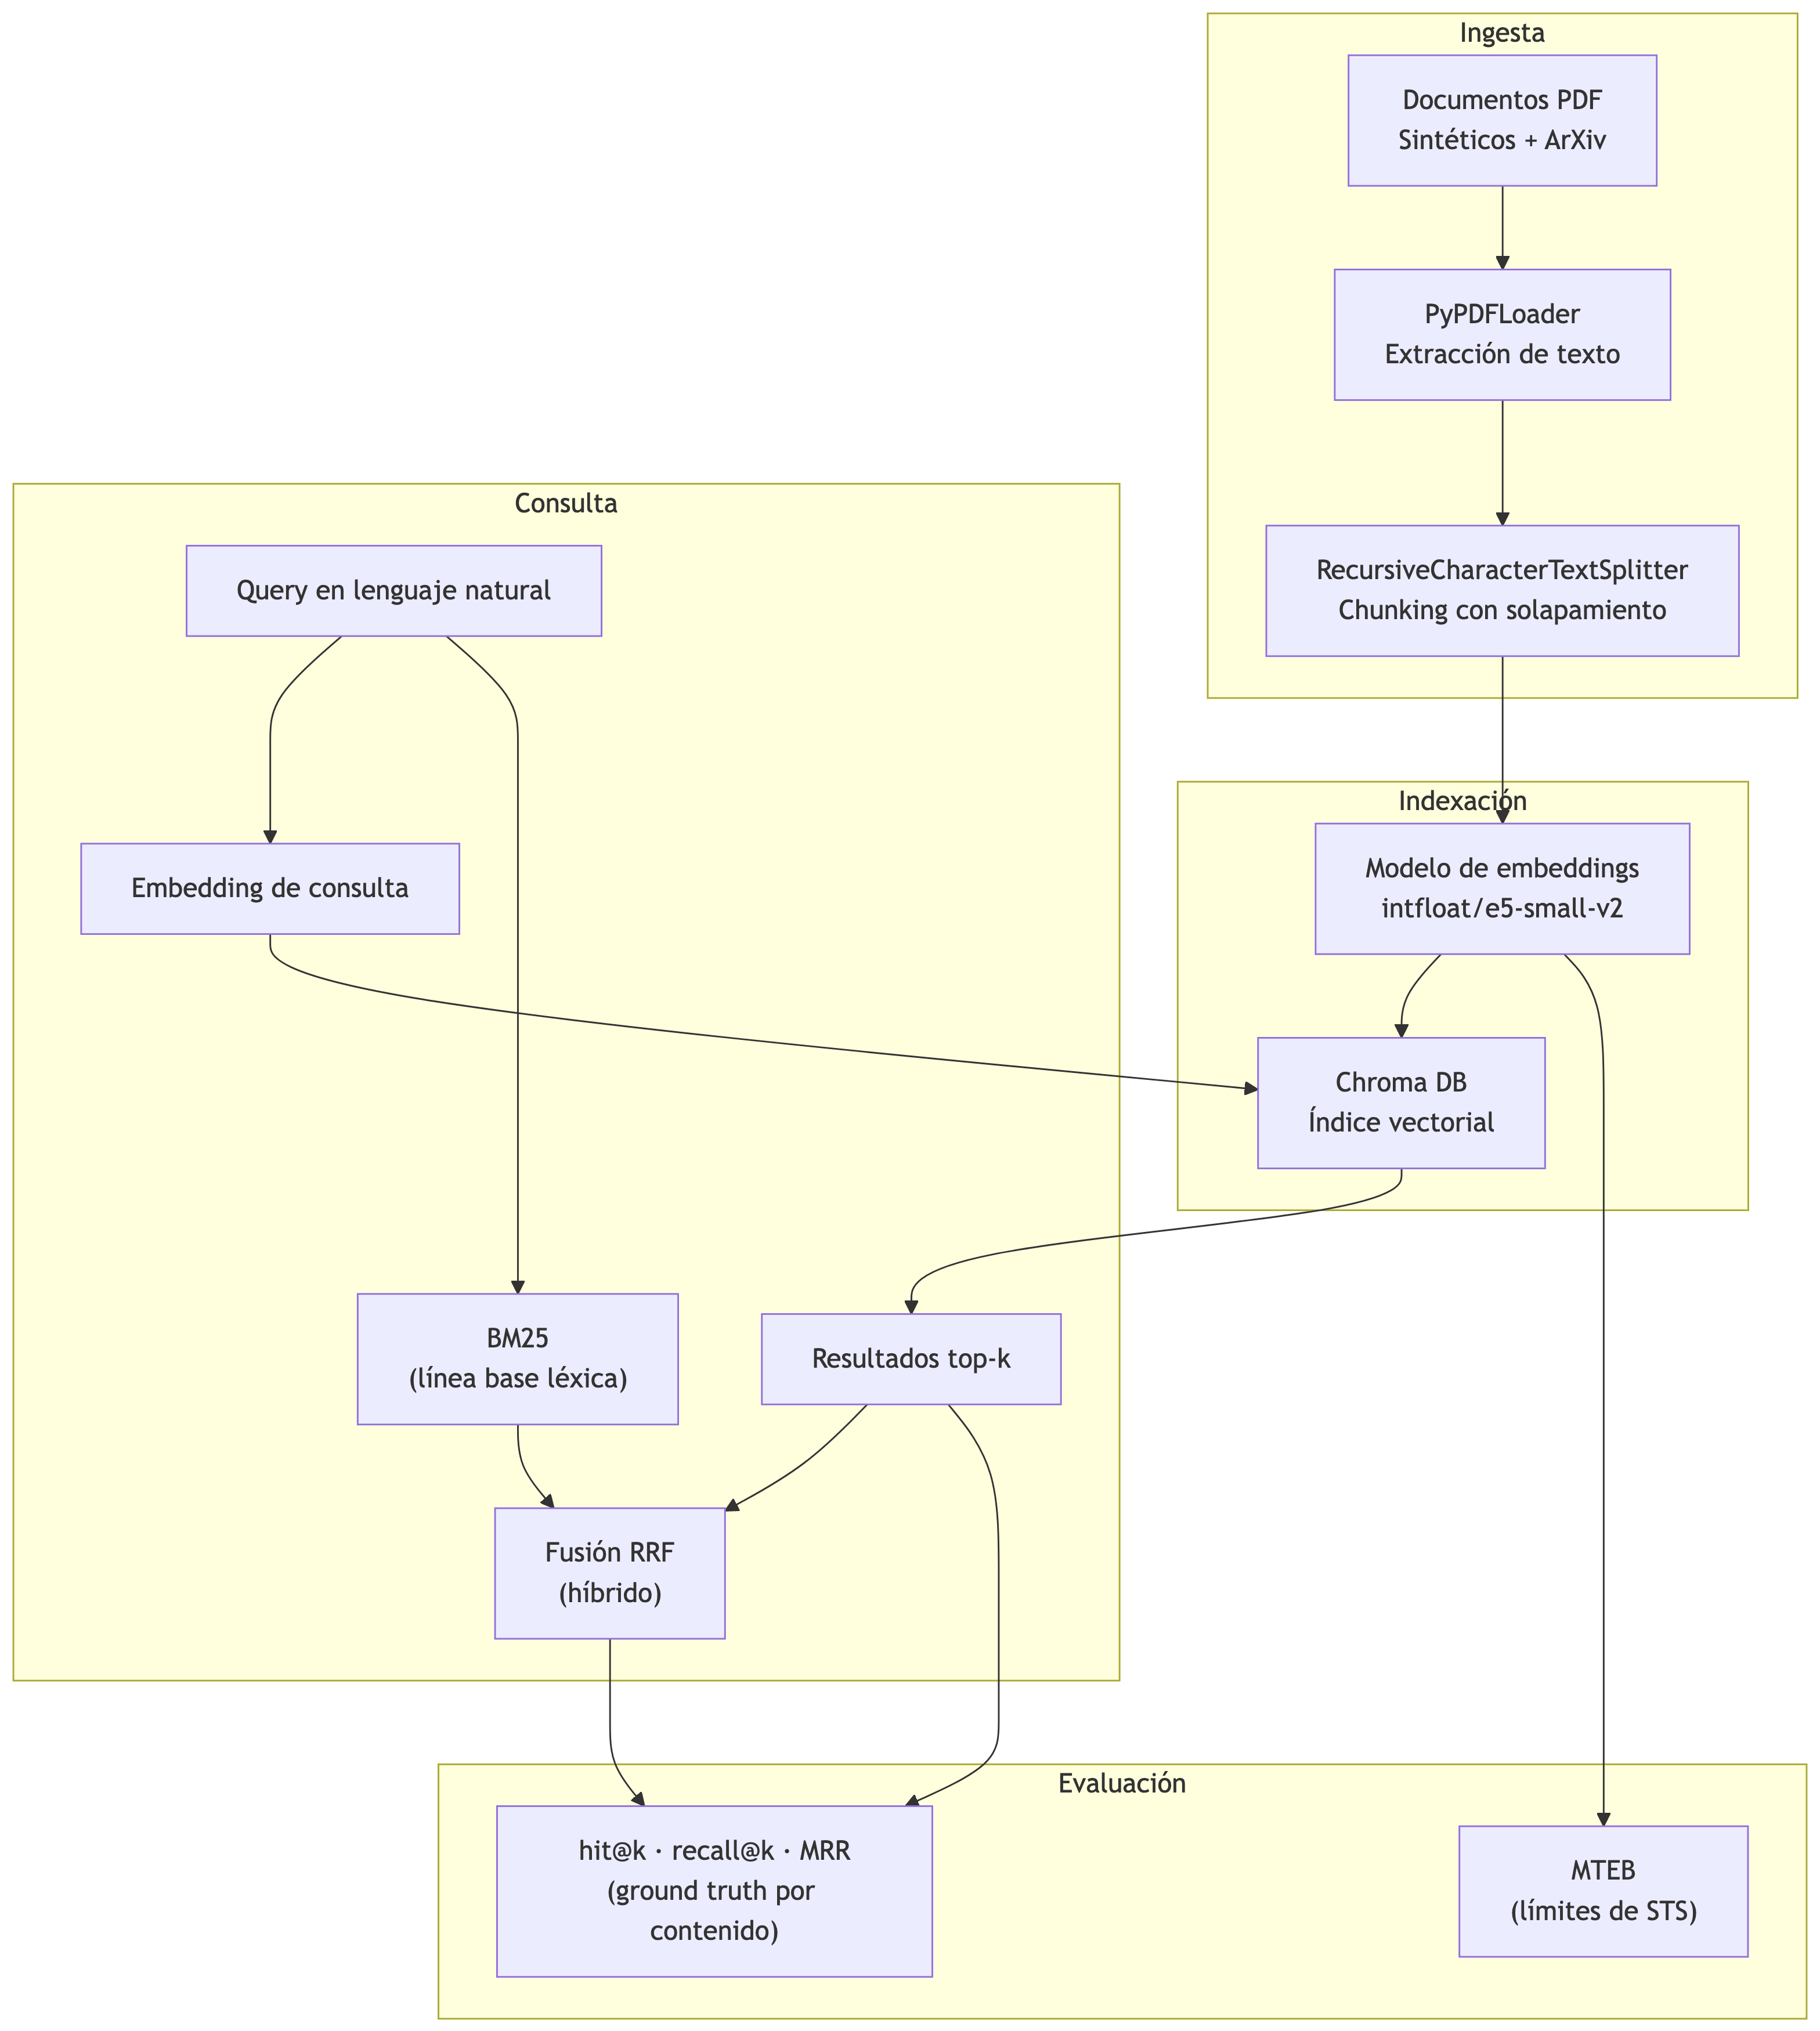
<figcaption>Figure 1</figcaption>
</figure>

# References

Muennighoff, N., Tazi, N., Magne, L., & Reimers, N. (2023). MTEB:
Massive text embedding benchmark. *Proceedings of the 17th Conference of
the European Chapter of the Association for Computational Linguistics
(EACL)*, 2014–2037. <https://doi.org/10.18653/v1/2023.eacl-main.148>

Thakur, N., Reimers, N., Rücklé, A., Srivastava, A., & Gurevych, I.
(2021). BEIR: A heterogeneous benchmark for zero-shot evaluation of
information retrieval models. *Proceedings of the Neural Information
Processing Systems Track on Datasets and Benchmarks*.
<https://arxiv.org/abs/2104.08663>